# Modelagem de Risco de Credito com AutoML, Optuna e Top 3 Modelos

Notebook derivado de `modelagem_risco_credito_feature_selection_automl.ipynb`, adicionando benchmark automatizado de modelos, tuning com Optuna e selecao objetiva do Top 3.

## Escopo

1. Entender o problema de negocio e a variavel alvo `loan_status`.
2. Fazer a divisao estratificada em `80% treino`, `10% teste` e `10% implementacao` antes da analise aprofundada.
3. Executar EDA orientada a qualidade de dados e separacao entre bons e maus pagadores.
4. Construir features derivadas com racional de negocio.
5. Selecionar atributos com combinacao de informacao mutua e importancia de modelo.
6. Treinar um baseline e conferir o comportamento no conjunto reservado para implementacao.
7. Rodar um benchmark automatizado entre multiplas familias de modelos.
8. Aplicar Optuna nas 3 melhores familias e eleger o Top 3 final.

In [11]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42
TARGET = "loan_status"
DATA_PATH = Path("../data/credit_risk_dataset.csv")

## 1. Carregamento e entendimento do problema

Pergunta analitica: dado o perfil do cliente e do emprestimo, qual a probabilidade de inadimplencia (`loan_status = 1`)?

Como se trata de classificacao binaria para risco de credito, as decisoes mais importantes aqui sao:

- preservar a distribuicao do alvo entre os subconjuntos;
- evitar leakage usando apenas treino para analise aprofundada e selecao de atributos;
- reservar um conjunto adicional de implementacao para uma checagem final de comportamento do pipeline.

In [12]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Arquivo nao encontrado: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df[TARGET] = pd.to_numeric(df[TARGET], errors="raise").astype(int)

quality_summary = pd.DataFrame(
    {
        "metric": ["rows", "columns", "duplicate_rows", "target_event_rate"],
        "value": [len(df), df.shape[1], int(df.duplicated().sum()), df[TARGET].mean()],
    }
)

display(quality_summary)
display(df.head())

,metric,value
0,rows,"32,581.0000"
1,columns,12.0000
2,duplicate_rows,165.0000
3,target_event_rate,0.2182


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0000,PERSONAL,D,35000,16.0200,1,0.5900,Y,3
1,21,9600,OWN,5.0000,EDUCATION,B,1000,11.1400,0,0.1000,N,2
2,25,9600,MORTGAGE,1.0000,MEDICAL,C,5500,12.8700,1,0.5700,N,3
3,23,65500,RENT,4.0000,MEDICAL,C,35000,15.2300,1,0.5300,N,2
4,24,54400,RENT,8.0000,MEDICAL,C,35000,14.2700,1,0.5500,Y,4


### Estrutura do problema

,numeric_features,categorical_features
0,7,4


,class,count,share
0,0,25473,0.7818
1,1,7108,0.2182


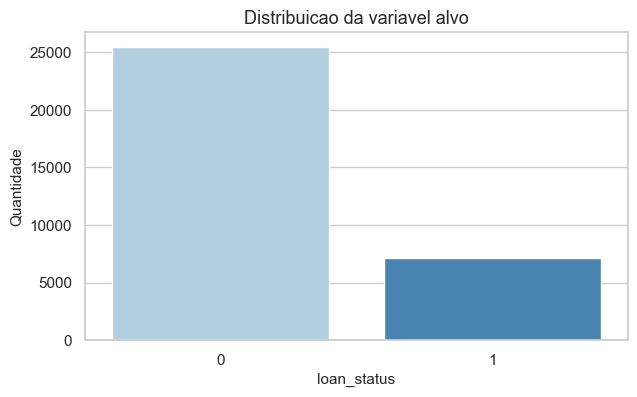

In [13]:
feature_columns = [column for column in df.columns if column != TARGET]
numeric_columns_raw = df[feature_columns].select_dtypes(include=[np.number]).columns.tolist()
categorical_columns_raw = df[feature_columns].select_dtypes(exclude=[np.number]).columns.tolist()

target_profile = pd.DataFrame(
    {
        "class": df[TARGET].value_counts().sort_index().index,
        "count": df[TARGET].value_counts().sort_index().values,
        "share": df[TARGET].value_counts(normalize=True).sort_index().values,
    }
)

display(Markdown("### Estrutura do problema"))
display(pd.DataFrame({"numeric_features": [len(numeric_columns_raw)], "categorical_features": [len(categorical_columns_raw)]}))
display(target_profile)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x=TARGET, palette="Blues", ax=ax)
ax.set_title("Distribuicao da variavel alvo")
ax.set_xlabel("loan_status")
ax.set_ylabel("Quantidade")
plt.show()

## 2. Divisao estratificada `80/10/10`

A divisao e feita em duas etapas para manter a estratificacao:

- primeiro, separamos `10%` para `implementation_df`;
- depois, dividimos os `90%` restantes em `train_df` e `test_df`, resultando em `80%` e `10%` do total.

A partir daqui, toda a analise detalhada e o processo de selecao usam apenas `train_df`.

In [14]:
train_full_df, implementation_df = train_test_split(
    df,
    test_size=0.10,
    stratify=df[TARGET],
    random_state=RANDOM_STATE,
)

train_df, test_df = train_test_split(
    train_full_df,
    test_size=(1 / 9),
    stratify=train_full_df[TARGET],
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame(
    [
        {"split": "train", "rows": len(train_df), "share": len(train_df) / len(df), "default_rate": train_df[TARGET].mean()},
        {"split": "test", "rows": len(test_df), "share": len(test_df) / len(df), "default_rate": test_df[TARGET].mean()},
        {"split": "implementation", "rows": len(implementation_df), "share": len(implementation_df) / len(df), "default_rate": implementation_df[TARGET].mean()},
    ]
)

display(split_summary)

assert len(train_df) + len(test_df) + len(implementation_df) == len(df)
assert abs(split_summary["share"].sum() - 1.0) < 1e-9

,split,rows,share,default_rate
0,train,26064,0.8000,0.2182
1,test,3258,0.1000,0.2182
2,implementation,3259,0.1000,0.2182


## 3. Analise exploratoria (EDA)

A EDA abaixo usa apenas `train_df` para evitar contaminacao dos conjuntos reservados. O foco aqui e entender qualidade, distribuicoes e sinais de separacao entre adimplentes e inadimplentes.

### Qualidade dos dados no treino

,feature,missing_share
0,loan_int_rate,0.0958
1,person_emp_length,0.0282
2,person_age,0.0000
3,person_home_ownership,0.0000
4,person_income,0.0000
5,loan_grade,0.0000
6,loan_intent,0.0000
7,loan_amnt,0.0000
8,loan_percent_income,0.0000
9,cb_person_default_on_file,0.0000


,count,mean,std,min,25%,50%,75%,max
person_income,"26,064.0000","65,934.0234","51,599.8980","4,000.0000","38,592.0000","55,000.0000","79,895.5000","2,039,784.0000"
loan_amnt,"26,064.0000","9,616.3146","6,328.3741",500.0000,"5,000.0000","8,000.0000","12,250.0000","35,000.0000"
person_age,"26,064.0000",27.7261,6.3316,20.0000,23.0000,26.0000,30.0000,144.0000
person_emp_length,"25,330.0000",4.7976,4.1721,0.0000,2.0000,4.0000,7.0000,123.0000
cb_person_cred_hist_length,"26,064.0000",5.7995,4.0533,2.0000,3.0000,4.0000,8.0000,30.0000
loan_int_rate,"23,567.0000",11.0134,3.2419,5.4200,7.9000,10.9900,13.4700,23.2200
loan_percent_income,"26,064.0000",0.1704,0.1067,0.0000,0.0900,0.1500,0.2300,0.8300


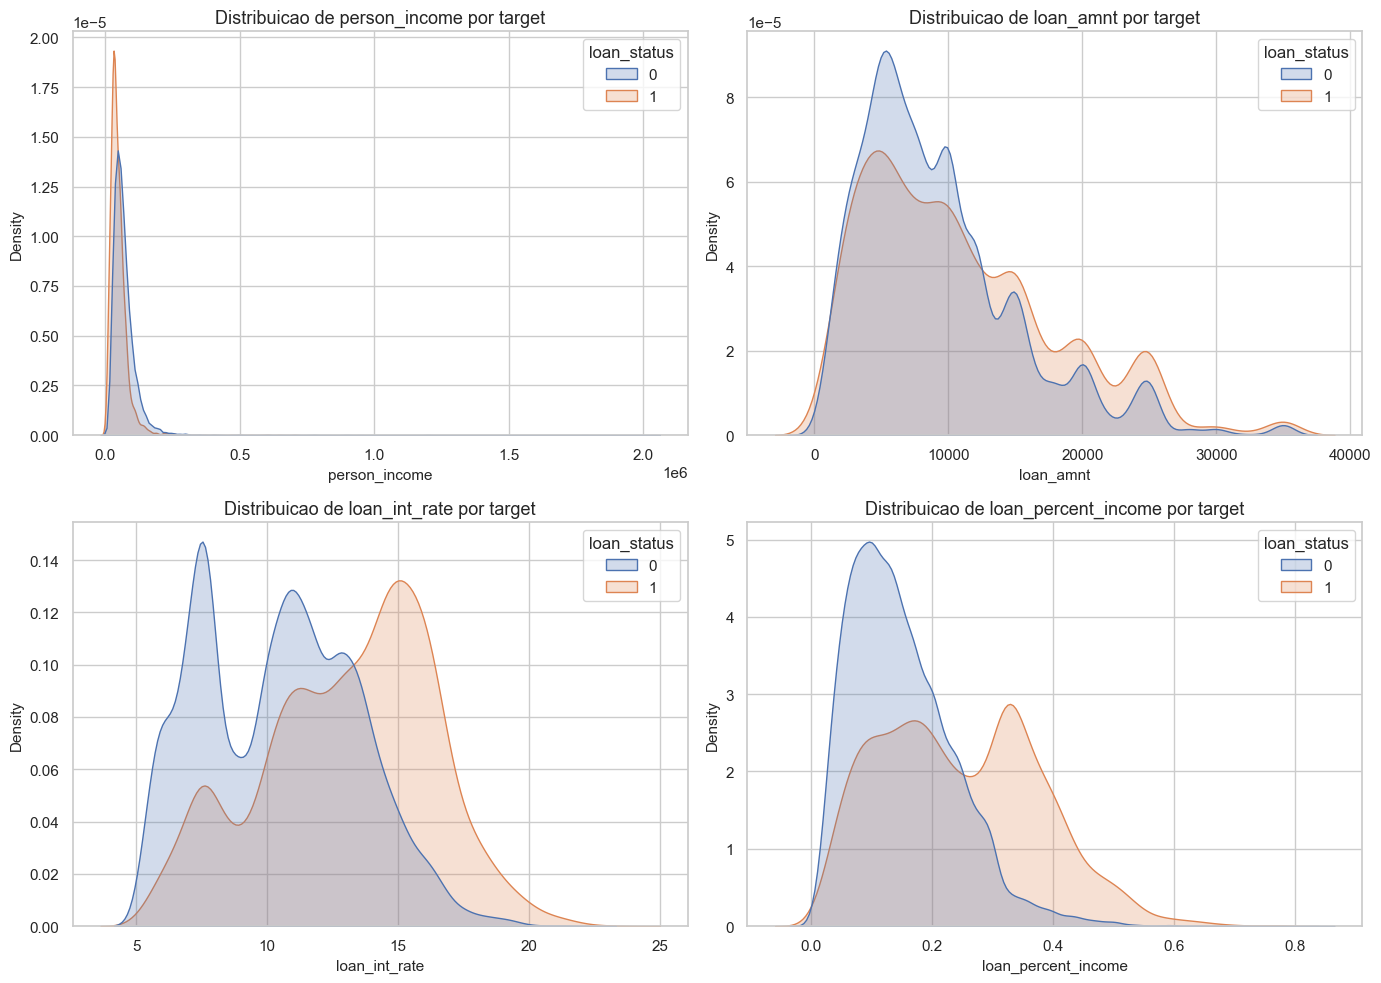

In [15]:
train_features = train_df.drop(columns=TARGET)
train_target = train_df[TARGET]

numeric_columns = train_features.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns = train_features.select_dtypes(exclude=[np.number]).columns.tolist()

missing_summary = (
    train_features.isna().mean().sort_values(ascending=False).rename("missing_share").reset_index().rename(columns={"index": "feature"})
)

numeric_summary = train_features[numeric_columns].describe().T.sort_values("std", ascending=False)

display(Markdown("### Qualidade dos dados no treino"))
display(missing_summary)
display(numeric_summary)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
key_numeric_features = ["person_income", "loan_amnt", "loan_int_rate", "loan_percent_income"]

for ax, feature in zip(axes.flatten(), key_numeric_features):
    sns.kdeplot(data=train_df, x=feature, hue=TARGET, fill=True, common_norm=False, ax=ax)
    ax.set_title(f"Distribuicao de {feature} por target")

plt.tight_layout()
plt.show()

,feature,person_home_ownership,event_rate,count,loan_intent,loan_grade,cb_person_default_on_file
0,person_home_ownership,RENT,0.3173,13144,NaN,NaN,NaN
1,person_home_ownership,OTHER,0.2907,86,NaN,NaN,NaN
2,person_home_ownership,MORTGAGE,0.1243,10750,NaN,NaN,NaN
3,person_home_ownership,OWN,0.0739,2084,NaN,NaN,NaN
4,loan_intent,NaN,0.2845,4193,DEBTCONSOLIDATION,NaN,NaN
5,loan_intent,NaN,0.2623,4865,MEDICAL,NaN,NaN
6,loan_intent,NaN,0.2600,2869,HOMEIMPROVEMENT,NaN,NaN
7,loan_intent,NaN,0.2036,4401,PERSONAL,NaN,NaN
8,loan_intent,NaN,0.1737,5186,EDUCATION,NaN,NaN
9,loan_intent,NaN,0.1481,4550,VENTURE,NaN,NaN


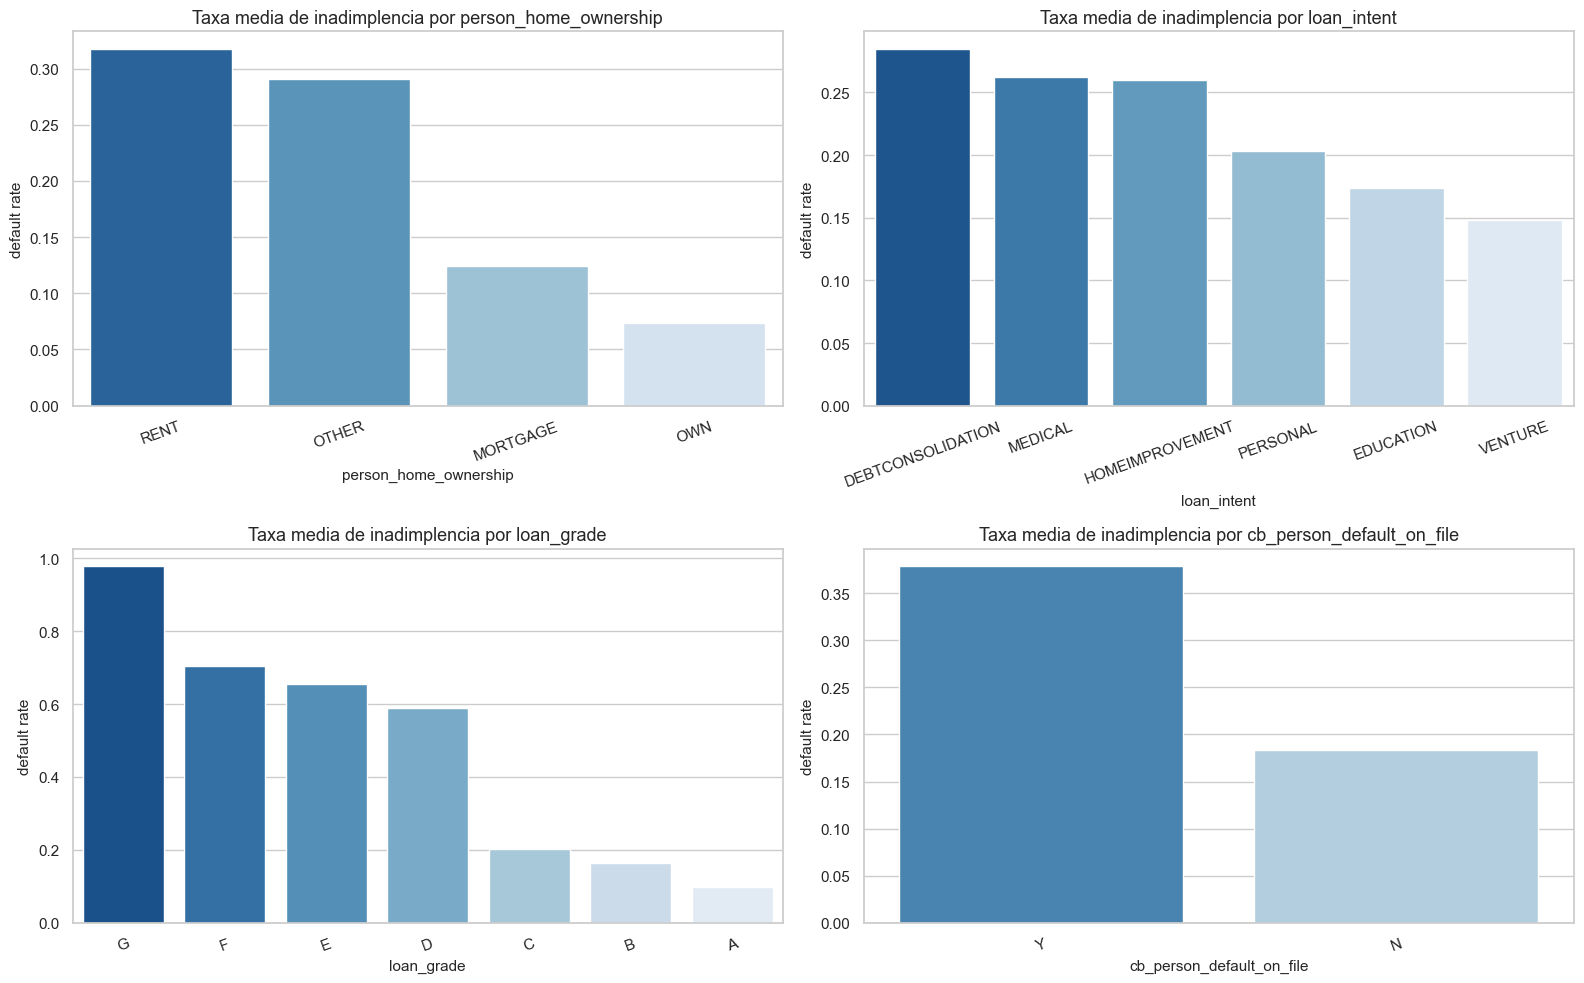

In [16]:
categorical_risk_profile = []

for feature in categorical_columns:
    grouped = (
        train_df.groupby(feature, dropna=False)[TARGET]
        .agg(event_rate="mean", count="size")
        .sort_values(["event_rate", "count"], ascending=[False, False])
        .reset_index()
    )
    grouped.insert(0, "feature", feature)
    categorical_risk_profile.append(grouped)

categorical_risk_profile = pd.concat(categorical_risk_profile, ignore_index=True)
display(categorical_risk_profile)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plot_features = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

for ax, feature in zip(axes.flatten(), plot_features):
    ordered = (
        train_df.groupby(feature)[TARGET].mean().sort_values(ascending=False).index
    )
    sns.barplot(data=train_df, x=feature, y=TARGET, order=ordered, estimator=np.mean, errorbar=None, palette="Blues_r", ax=ax)
    ax.set_title(f"Taxa media de inadimplencia por {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("default rate")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 4. Feature engineering

Nesta etapa, o objetivo nao e apenas aumentar o numero de colunas, mas criar sinais mais proximos da dinamica de risco:

- razoes entre renda, valor do emprestimo e historico de credito;
- transformacoes logaritmicas para variaveis assimetricas;
- flags e buckets com interpretacao de negocio;
- tratamento robusto de ausentes e categoricas na etapa de preprocessamento.

In [17]:
class DomainFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.input_features_ = X.columns.tolist()
        return self

    def transform(self, X):
        X = X.copy()

        income = X["person_income"].replace(0, np.nan)
        age = X["person_age"].replace(0, np.nan)
        credit_hist = X["cb_person_cred_hist_length"].replace(0, np.nan)
        emp_length = X["person_emp_length"]
        loan_share = X["loan_percent_income"].replace(0, np.nan)

        X["loan_to_income_ratio"] = X["loan_amnt"] / income
        X["credit_hist_to_age_ratio"] = X["cb_person_cred_hist_length"] / age
        X["emp_length_to_age_ratio"] = emp_length / age
        X["income_per_credit_year"] = X["person_income"] / (credit_hist + 1)
        X["rate_x_amount"] = X["loan_int_rate"] * X["loan_amnt"]
        X["rate_to_income_share"] = X["loan_int_rate"] / loan_share
        X["person_income_log"] = np.log1p(X["person_income"].clip(lower=0))
        X["loan_amnt_log"] = np.log1p(X["loan_amnt"].clip(lower=0))
        X["person_emp_length_missing_flag"] = X["person_emp_length"].isna().astype(int)
        X["loan_int_rate_missing_flag"] = X["loan_int_rate"].isna().astype(int)
        X["high_income_commitment"] = (X["loan_percent_income"] >= 0.35).astype(int)
        X["has_default_history"] = (X["cb_person_default_on_file"] == "Y").astype(int)
        X["age_bucket"] = pd.cut(X["person_age"], bins=[0, 25, 35, 45, 60, np.inf], labels=["18_25", "26_35", "36_45", "46_60", "60_plus"])
        X["employment_bucket"] = pd.cut(X["person_emp_length"], bins=[-np.inf, 0, 2, 5, 10, np.inf], labels=["missing_or_zero", "1_2", "3_5", "6_10", "10_plus"])

        ratio_columns = [
            "loan_to_income_ratio",
            "credit_hist_to_age_ratio",
            "emp_length_to_age_ratio",
            "income_per_credit_year",
            "rate_to_income_share",
        ]

        X[ratio_columns] = X[ratio_columns].replace([np.inf, -np.inf], np.nan)
        return X


feature_engineer = DomainFeatureEngineer()

X_train = train_df.drop(columns=TARGET)
y_train = train_df[TARGET]
X_test = test_df.drop(columns=TARGET)
y_test = test_df[TARGET]
X_implementation = implementation_df.drop(columns=TARGET)
y_implementation = implementation_df[TARGET]

X_train_fe = feature_engineer.fit_transform(X_train)
X_test_fe = feature_engineer.transform(X_test)
X_implementation_fe = feature_engineer.transform(X_implementation)

engineered_columns = sorted(set(X_train_fe.columns) - set(X_train.columns))
display(pd.DataFrame({"engineered_feature": engineered_columns}))

,engineered_feature
0,age_bucket
1,credit_hist_to_age_ratio
2,emp_length_to_age_ratio
3,employment_bucket
4,has_default_history
5,high_income_commitment
6,income_per_credit_year
7,loan_amnt_log
8,loan_int_rate_missing_flag
9,loan_to_income_ratio


In [18]:
model_numeric_columns = X_train_fe.select_dtypes(include=[np.number]).columns.tolist()
model_categorical_columns = X_train_fe.select_dtypes(exclude=[np.number]).columns.tolist()
numeric_columns_fe = model_numeric_columns
categorical_columns_fe = model_categorical_columns

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, model_numeric_columns),
        ("cat", categorical_pipeline, model_categorical_columns),
    ],
    remainder="drop",
    sparse_threshold=0.0,
)

X_train_processed = preprocessor.fit_transform(X_train_fe)
X_test_processed = preprocessor.transform(X_test_fe)
X_implementation_processed = preprocessor.transform(X_implementation_fe)

feature_names = preprocessor.get_feature_names_out()
display(pd.DataFrame({"processed_feature": feature_names}).head(20))
print(f"Matriz de treino apos preprocessamento: {X_train_processed.shape}")

,processed_feature
0,num__person_age
1,num__person_income
2,num__person_emp_length
3,num__loan_amnt
4,num__loan_int_rate
5,num__loan_percent_income
6,num__cb_person_cred_hist_length
7,num__loan_to_income_ratio
8,num__credit_hist_to_age_ratio
9,num__emp_length_to_age_ratio


Matriz de treino apos preprocessamento: (26064, 48)


## 4.1 Balanceamento com SMOTE

Como a base e desbalanceada, o balanceamento e feito apenas no conjunto de treino ja preprocessado. `test` e `implementation` continuam intocados para preservar a avaliacao.

In [19]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

balance_summary = pd.DataFrame(
    [
        {
            "stage": "before_smote",
            "rows": len(y_train),
            "class_0": int((y_train == 0).sum()),
            "class_1": int((y_train == 1).sum()),
            "default_rate": y_train.mean(),
        },
        {
            "stage": "after_smote",
            "rows": len(y_train_resampled),
            "class_0": int((y_train_resampled == 0).sum()),
            "class_1": int((y_train_resampled == 1).sum()),
            "default_rate": y_train_resampled.mean(),
        },
    ]
)

display(balance_summary)
print(f"Matriz de treino apos SMOTE: {X_train_resampled.shape}")

,stage,rows,class_0,class_1,default_rate
0,before_smote,26064,20378,5686,0.2182
1,after_smote,40756,20378,20378,0.5000


Matriz de treino apos SMOTE: (40756, 48)


## 5. Feature selection

A escolha de atributos madura combina negocio, estatistica e comportamento real do modelo.

Regra 1: antes de qualquer tecnica, cada atributo precisa passar por tres perguntas.

- ele faz sentido causalmente?
- ele estara disponivel em producao?
- ele nao contem leakage?

Depois disso, entram as tecnicas praticas:

- correlacao: Pearson entre numericas e point-biserial entre numericas e target binario;
- importancia baseada em modelo: `RandomForestClassifier` e, quando fizer sentido, `XGBoost`;
- SHAP: uma das abordagens mais fortes para explicar impacto real dos atributos;
- testes estatisticos: ANOVA e Chi-square;
- remocao de atributos ruins: multicolinearidade, missing excessivo e variancia nula.

In [20]:
from scipy.stats import chi2_contingency, f_oneway, pointbiserialr
import importlib.util

feature_governance = pd.DataFrame(
    {
        "feature": X_train_fe.columns,
        "dtype": X_train_fe.dtypes.astype(str).values,
        "causal_rationale": "Validar com negocio",
        "available_in_production": "Validar",
        "leakage_risk": "Baixo, salvo evidencia contraria",
    }
)

numeric_columns_fe = X_train_fe.select_dtypes(include=[np.number]).columns.tolist()
categorical_columns_fe = X_train_fe.select_dtypes(exclude=[np.number]).columns.tolist()

point_biserial_rows = []
for feature in numeric_columns_fe:
    valid = X_train_fe[[feature]].join(y_train).dropna()
    if valid[feature].nunique() < 2:
        corr_value, p_value = np.nan, np.nan
    else:
        corr_value, p_value = pointbiserialr(valid[TARGET], valid[feature])
    point_biserial_rows.append(
        {
            "feature": feature,
            "point_biserial_corr": corr_value,
            "abs_corr": abs(corr_value) if pd.notna(corr_value) else np.nan,
            "p_value": p_value,
        }
    )

target_correlation_df = pd.DataFrame(point_biserial_rows).sort_values("abs_corr", ascending=False)
numeric_corr_matrix = X_train_fe[numeric_columns_fe].corr(method="pearson")

high_corr_pairs = []
for i, left in enumerate(numeric_corr_matrix.columns):
    for j, right in enumerate(numeric_corr_matrix.columns):
        if j <= i:
            continue
        corr_value = numeric_corr_matrix.iloc[i, j]
        if pd.notna(corr_value) and abs(corr_value) >= 0.75:
            high_corr_pairs.append(
                {"feature_left": left, "feature_right": right, "pearson_corr": corr_value}
            )

high_corr_pairs_df = pd.DataFrame(high_corr_pairs)
if not high_corr_pairs_df.empty:
    high_corr_pairs_df = high_corr_pairs_df.sort_values("pearson_corr", key=lambda values: values.abs(), ascending=False)

anova_rows = []
for feature in numeric_columns_fe:
    group_0 = X_train_fe.loc[y_train == 0, feature].dropna()
    group_1 = X_train_fe.loc[y_train == 1, feature].dropna()
    if len(group_0) > 1 and len(group_1) > 1 and group_0.nunique() > 1 and group_1.nunique() > 1:
        f_stat, p_value = f_oneway(group_0, group_1)
    else:
        f_stat, p_value = np.nan, np.nan
    anova_rows.append({"feature": feature, "anova_f_stat": f_stat, "anova_p_value": p_value})

anova_df = pd.DataFrame(anova_rows).sort_values("anova_f_stat", ascending=False)

chi2_rows = []
for feature in categorical_columns_fe:
    feature_values = X_train_fe[feature].astype("object").where(X_train_fe[feature].notna(), "Missing")
    contingency_table = pd.crosstab(feature_values, y_train)
    chi2_stat, p_value, _, _ = chi2_contingency(contingency_table)
    chi2_rows.append({"feature": feature, "chi2_stat": chi2_stat, "chi2_p_value": p_value})

chi2_df = pd.DataFrame(chi2_rows).sort_values("chi2_stat", ascending=False)

feature_quality_df = pd.DataFrame(
    {
        "feature": X_train_fe.columns,
        "missing_share": X_train_fe.isna().mean().values,
        "unique_values": X_train_fe.nunique(dropna=False).values,
        "top_frequency_share": [
            X_train_fe[column].value_counts(dropna=False, normalize=True).iloc[0]
            for column in X_train_fe.columns
        ],
    }
)
feature_quality_df["remove_for_missing"] = feature_quality_df["missing_share"] >= 0.40
feature_quality_df["remove_for_no_variance"] = feature_quality_df["unique_values"] <= 1
feature_quality_df["near_zero_variance"] = feature_quality_df["top_frequency_share"] >= 0.995

feature_selection_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=30,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
feature_selection_rf.fit(X_train_resampled, y_train_resampled)
rf_importance_df = pd.DataFrame(
    {"feature": feature_names, "rf_importance": feature_selection_rf.feature_importances_}
).sort_values("rf_importance", ascending=False)

display(Markdown("### Checklist de negocio"))
display(feature_governance.head(20))
display(Markdown("### Correlacao com o target"))
display(target_correlation_df)
display(Markdown("### Pares com alta correlacao entre features"))
display(high_corr_pairs_df)
display(Markdown("### Testes estatisticos"))
display(anova_df)
display(chi2_df)
display(Markdown("### Sinais para remocao de atributos ruins"))
display(feature_quality_df.sort_values(["remove_for_missing", "remove_for_no_variance", "near_zero_variance", "missing_share"], ascending=[False, False, False, False]))
display(Markdown("### Importancia de atributos baseada em modelo"))
display(rf_importance_df.head(25))

if importlib.util.find_spec("shap") is None:
    display(Markdown("### SHAP\n`shap` nao esta instalado neste ambiente. Se quiser ativar esta etapa, instale com `pip install shap`."))
else:
    import shap
    shap_sample = pd.DataFrame(X_train_resampled, columns=feature_names).sample(n=min(2000, len(X_train_resampled)), random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(feature_selection_rf)
    shap_values = explainer.shap_values(shap_sample)
    shap_array = shap_values[1] if isinstance(shap_values, list) else shap_values
    display(Markdown("### SHAP\nSHAP mostra o impacto real de cada atributo no score do modelo."))
    shap.summary_plot(shap_array, shap_sample, show=True)

### Checklist de negocio

,feature,dtype,causal_rationale,available_in_production,leakage_risk
0,person_age,int64,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
1,person_income,int64,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
2,person_home_ownership,str,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
3,person_emp_length,float64,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
4,loan_intent,str,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
5,loan_grade,str,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
6,loan_amnt,int64,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
7,loan_int_rate,float64,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
8,loan_percent_income,float64,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"
9,cb_person_default_on_file,str,Validar com negocio,Validar,"Baixo, salvo evidencia contraria"


### Correlacao com o target

,feature,point_biserial_corr,abs_corr,p_value
7,loan_to_income_ratio,0.3849,0.3849,0.0000
5,loan_percent_income,0.3785,0.3785,0.0000
4,loan_int_rate,0.3353,0.3353,0.0000
17,high_income_commitment,0.3335,0.3335,0.0000
13,person_income_log,-0.2820,0.2820,0.0000
11,rate_x_amount,0.2153,0.2153,0.0000
18,has_default_history,0.1797,0.1797,0.0000
1,person_income,-0.1696,0.1696,0.0000
10,income_per_credit_year,-0.1596,0.1596,0.0000
3,loan_amnt,0.1052,0.1052,0.0000


### Pares com alta correlacao entre features

...

### Sinais para remocao de atributos ruins

,feature,missing_share,unique_values,top_frequency_share,remove_for_missing,remove_for_no_variance,near_zero_variance
16,rate_to_income_share,0.0960,6156,0.0960,False,False,False
7,loan_int_rate,0.0958,341,0.0958,False,False,False
15,rate_x_amount,0.0958,8320,0.0958,False,False,False
3,person_emp_length,0.0282,35,0.1244,False,False,False
13,emp_length_to_age_ratio,0.0282,471,0.1244,False,False,False
24,employment_bucket,0.0282,6,0.2841,False,False,False
0,person_age,0.0000,56,0.1196,False,False,False
1,person_income,0.0000,3698,0.0328,False,False,False
2,person_home_ownership,0.0000,4,0.5043,False,False,False
4,loan_intent,0.0000,6,0.1990,False,False,False


### Importancia de atributos baseada em modelo

,feature,rf_importance
32,cat__loan_grade_D,0.1205
5,num__loan_percent_income,0.1085
7,num__loan_to_income_ratio,0.1076
22,cat__person_home_ownership_RENT,0.0865
4,num__loan_int_rate,0.0848
13,num__person_income_log,0.0569
1,num__person_income,0.0524
19,cat__person_home_ownership_MORTGAGE,0.0481
17,num__high_income_commitment,0.0331
29,cat__loan_grade_A,0.0312


### SHAP
`shap` nao esta instalado neste ambiente. Se quiser ativar esta etapa, instale com `pip install shap`.

In [21]:
mi_scores = mutual_info_classif(X_train_resampled, y_train_resampled, random_state=RANDOM_STATE)

selector_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=30,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
selector_model.fit(X_train_resampled, y_train_resampled)

selection_df = pd.DataFrame(
    {
        "feature": feature_names,
        "mutual_info": mi_scores,
        "rf_importance": selector_model.feature_importances_,
    }
)

selection_df["mi_rank_pct"] = selection_df["mutual_info"].rank(pct=True, ascending=True)
selection_df["rf_rank_pct"] = selection_df["rf_importance"].rank(pct=True, ascending=True)
selection_df["combined_score"] = 0.5 * selection_df["mi_rank_pct"] + 0.5 * selection_df["rf_rank_pct"]
selection_df = selection_df.sort_values("combined_score", ascending=False).reset_index(drop=True)

top_k = max(15, int(np.ceil(len(selection_df) * 0.30)))
selected_feature_names = selection_df.loc[: top_k - 1, "feature"].tolist()
selected_mask = np.isin(feature_names, selected_feature_names)
selected_feature_array = feature_names[selected_mask]

X_train_selected = X_train_processed[:, selected_mask]
X_train_resampled_selected = X_train_resampled[:, selected_mask]
X_test_selected = X_test_processed[:, selected_mask]
X_implementation_selected = X_implementation_processed[:, selected_mask]

display(selection_df.head(25))
print(f"Features apos preprocessamento: {len(feature_names)}")
print(f"Features selecionadas: {len(selected_feature_array)}")

,feature,mutual_info,rf_importance,mi_rank_pct,rf_rank_pct,combined_score
0,num__loan_percent_income,0.3467,0.1085,1.0000,0.9792,0.9896
1,num__loan_int_rate,0.3250,0.0848,0.9792,0.9167,0.9479
2,num__person_income_log,0.2792,0.0569,0.9375,0.8958,0.9167
3,num__person_income,0.2758,0.0524,0.9167,0.8750,0.8958
4,num__loan_to_income_ratio,0.2178,0.1076,0.7917,0.9583,0.8750
5,cat__loan_grade_D,0.0847,0.1205,0.6667,1.0000,0.8333
6,cat__person_home_ownership_RENT,0.0995,0.0865,0.6875,0.9375,0.8125
7,num__rate_to_income_share,0.2339,0.0200,0.8333,0.7500,0.7917
8,num__loan_amnt,0.2443,0.0129,0.8750,0.6250,0.7500
9,cat__person_home_ownership_MORTGAGE,0.0704,0.0481,0.6458,0.8542,0.7500


Features apos preprocessamento: 48
Features selecionadas: 15


## 6. Modelo inicial para conferir a implementacao

O objetivo aqui nao e fechar a melhor modelagem possivel, mas garantir que:

- o pipeline de dados funciona de ponta a ponta;
- as features selecionadas preservam poder preditivo;
- o conjunto `implementation_df` permanece intocado ate a checagem final.

In [22]:
model = LogisticRegression(
    solver="lbfgs",
    max_iter=4000,
    random_state=RANDOM_STATE,
)
model.fit(X_train_resampled_selected, y_train_resampled)


def evaluate_split(name, X, y, fitted_model, threshold=0.50):
    score = fitted_model.predict_proba(X)[:, 1]
    pred = (score >= threshold).astype(int)
    return {
        "split": name,
        "roc_auc": roc_auc_score(y, score),
        "average_precision": average_precision_score(y, score),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "predicted_event_rate": pred.mean(),
        "observed_event_rate": y.mean(),
    }


evaluation_df = pd.DataFrame(
    [
        evaluate_split("train", X_train_selected, y_train, model),
        evaluate_split("test", X_test_selected, y_test, model),
        evaluate_split("implementation", X_implementation_selected, y_implementation, model),
    ]
)

display(evaluation_df)

top_coefficients = pd.DataFrame(
    {
        "feature": selected_feature_array,
        "coefficient": model.coef_[0],
        "abs_coefficient": np.abs(model.coef_[0]),
    }
).sort_values("abs_coefficient", ascending=False)

display(top_coefficients.head(20))

,split,roc_auc,average_precision,precision,recall,f1,predicted_event_rate,observed_event_rate
0,train,0.8748,0.7224,0.5479,0.7782,0.6431,0.3099,0.2182
1,test,0.8797,0.7318,0.5445,0.7834,0.6424,0.3140,0.2182
2,implementation,0.8686,0.7189,0.5454,0.7693,0.6383,0.3078,0.2182


,feature,coefficient,abs_coefficient
4,num__loan_to_income_ratio,9.7864,9.7864
3,num__loan_percent_income,-8.5945,8.5945
11,cat__person_home_ownership_RENT,2.5960,2.5960
10,cat__person_home_ownership_MORTGAGE,1.9582,1.9582
14,cat__loan_grade_D,1.5789,1.5789
8,num__loan_amnt_log,-0.7938,0.7938
2,num__loan_int_rate,0.7121,0.7121
12,cat__loan_intent_DEBTCONSOLIDATION,0.5663,0.5663
7,num__person_income_log,-0.5475,0.5475
0,num__person_income,0.4632,0.4632


## 7. O que e AutoML?

AutoML, ou *Automated Machine Learning*, e o processo de automatizar o ciclo de criacao de modelos:

Escolher modelo  
Selecionar features  
Ajustar hiperparametros  
Treinar  
Avaliar

Objetivos principais:

- reduzir tempo de experimentacao;
- encontrar modelos fortes de forma automatizada;
- padronizar pipelines.

Um AutoML completo pode testar varios algoritmos, fazer preprocessing automatico, selecionar features, ajustar hiperparametros e escolher o melhor candidato. Ferramentas populares incluem `auto-sklearn`, `H2O AutoML`, `TPOT`, `PyCaret` e `Google AutoML`.

## 8. O que e Optuna?

Optuna e uma biblioteca de otimizacao de hiperparametros. Ela nao e um AutoML completo, mas resolve muito bem uma parte critica do fluxo: encontrar automaticamente combinacoes mais fortes de parametros para um algoritmo.

Na pratica, Optuna permite:

- definir um espaco de busca;
- otimizar metricas como `roc_auc`;
- usar *pruning* para interromper tentativas ruins cedo;
- acelerar a busca por configuracoes competitivas.

Ele costuma ser a melhor escolha quando o algoritmo ja foi definido e o foco passa a ser tuning.

## 9. AutoML pratico: benchmark automatizado de modelos

Aqui implementamos um AutoML leve e controlado: varios algoritmos sao avaliados automaticamente com validacao cruzada estratificada e `SMOTE` aplicado dentro de cada fold. O criterio principal de ranking e `ROC AUC`, com apoio de `average_precision` e `F1`.

In [23]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

automl_candidates = {
    "logistic_regression": LogisticRegression(solver="lbfgs", max_iter=4000, random_state=RANDOM_STATE),
    "random_forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "extra_trees": ExtraTreesClassifier(n_estimators=400, max_depth=10, min_samples_leaf=10, n_jobs=-1, random_state=RANDOM_STATE),
    "hist_gradient_boosting": HistGradientBoostingClassifier(max_depth=6, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
}

benchmark_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
automl_rows = []
trained_automl_models = {}

for model_name, estimator in automl_candidates.items():
    pipeline = ImbPipeline(
        steps=[
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("model", estimator),
        ]
    )

    cv_result = cross_validate(
        pipeline,
        X_train_selected,
        y_train,
        cv=benchmark_cv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
            "f1": "f1",
        },
        n_jobs=-1,
        return_train_score=False,
    )

    pipeline.fit(X_train_selected, y_train)
    trained_automl_models[model_name] = pipeline
    test_metrics = evaluate_split("test", X_test_selected, y_test, pipeline)
    implementation_metrics = evaluate_split("implementation", X_implementation_selected, y_implementation, pipeline)

    automl_rows.append(
        {
            "model": model_name,
            "cv_roc_auc_mean": cv_result["test_roc_auc"].mean(),
            "cv_roc_auc_std": cv_result["test_roc_auc"].std(),
            "cv_average_precision_mean": cv_result["test_average_precision"].mean(),
            "cv_f1_mean": cv_result["test_f1"].mean(),
            "test_roc_auc": test_metrics["roc_auc"],
            "test_average_precision": test_metrics["average_precision"],
            "implementation_roc_auc": implementation_metrics["roc_auc"],
            "implementation_average_precision": implementation_metrics["average_precision"],
        }
    )

automl_benchmark_df = pd.DataFrame(automl_rows).sort_values(
    ["cv_roc_auc_mean", "test_roc_auc", "implementation_roc_auc"],
    ascending=False,
).reset_index(drop=True)

top3_candidate_names = automl_benchmark_df.head(3)["model"].tolist()
display(automl_benchmark_df)
display(Markdown(f"### Top 3 apos benchmark automatizado\n{', '.join(top3_candidate_names)}"))

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean,cv_f1_mean,test_roc_auc,test_average_precision,implementation_roc_auc,implementation_average_precision
0,hist_gradient_boosting,0.9235,0.0057,0.8594,0.7634,0.9287,0.8633,0.9127,0.8464
1,random_forest,0.9040,0.0047,0.8340,0.7382,0.9033,0.8374,0.8917,0.8173
2,extra_trees,0.8905,0.0074,0.7960,0.7067,0.8885,0.8019,0.8792,0.7824
3,logistic_regression,0.8748,0.0071,0.7206,0.6401,0.8798,0.7298,0.8695,0.7179


### Top 3 apos benchmark automatizado
hist_gradient_boosting, random_forest, extra_trees

## 10. Optuna: tuning das 3 melhores familias

Depois do benchmark automatizado, o Optuna ajusta hiperparametros apenas das tres melhores familias. Isso reduz custo computacional e concentra o tuning onde ja existe sinal de performance.

In [25]:
OPTUNA_TRIALS = 20
optuna_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)


def build_tunable_model(model_name, params):
    if model_name == "logistic_regression":
        return LogisticRegression(
            C=params["C"],
            solver="lbfgs",
            max_iter=4000,
            random_state=RANDOM_STATE,
        )

    if model_name == "random_forest":
        return RandomForestClassifier(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features=params["max_features"],
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )

    if model_name == "extra_trees":
        return ExtraTreesClassifier(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features=params["max_features"],
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )

    if model_name == "hist_gradient_boosting":
        return HistGradientBoostingClassifier(
            learning_rate=params["learning_rate"],
            max_depth=params["max_depth"],
            max_leaf_nodes=params["max_leaf_nodes"],
            min_samples_leaf=params["min_samples_leaf"],
            l2_regularization=params["l2_regularization"],
            random_state=RANDOM_STATE,
        )

    raise ValueError(f"Modelo nao suportado: {model_name}")


def sample_params(trial, model_name):
    if model_name == "logistic_regression":
        return {"C": trial.suggest_float("C", 1e-3, 50.0, log=True)}

    if model_name in {"random_forest", "extra_trees"}:
        return {
            "n_estimators": trial.suggest_int("n_estimators", 200, 700, step=100),
            "max_depth": trial.suggest_int("max_depth", 4, 16),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 30),
            "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        }

    if model_name == "hist_gradient_boosting":
        return {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 12),
            "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 15, 63),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 80),
            "l2_regularization": trial.suggest_float("l2_regularization", 1e-8, 1.0, log=True),
        }

    raise ValueError(f"Modelo nao suportado: {model_name}")


def optuna_objective(trial, model_name):
    params = sample_params(trial, model_name)
    estimator = build_tunable_model(model_name, params)
    pipeline = ImbPipeline(
        steps=[
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("model", estimator),
        ]
    )

    cv_scores = cross_validate(
        pipeline,
        X_train_selected,
        y_train,
        cv=optuna_cv,
        scoring="roc_auc",
        n_jobs=-1,
        return_train_score=False,
    )
    return cv_scores["test_score"].mean()


optuna_rows = []
best_tuned_models = {}

for rank_position, model_name in enumerate(top3_candidate_names, start=1):
    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE + rank_position)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(lambda trial, current_name=model_name: optuna_objective(trial, current_name), n_trials=OPTUNA_TRIALS, show_progress_bar=False)

    tuned_model = build_tunable_model(model_name, study.best_params)
    tuned_pipeline = ImbPipeline(
        steps=[
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("model", tuned_model),
        ]
    )
    tuned_pipeline.fit(X_train_selected, y_train)
    best_tuned_models[model_name] = tuned_pipeline

    test_metrics = evaluate_split("test", X_test_selected, y_test, tuned_pipeline)
    implementation_metrics = evaluate_split("implementation", X_implementation_selected, y_implementation, tuned_pipeline)

    optuna_rows.append(
        {
            "model": model_name,
            "optuna_best_cv_roc_auc": study.best_value,
            "test_roc_auc": test_metrics["roc_auc"],
            "test_average_precision": test_metrics["average_precision"],
            "test_f1": test_metrics["f1"],
            "implementation_roc_auc": implementation_metrics["roc_auc"],
            "implementation_average_precision": implementation_metrics["average_precision"],
            "implementation_f1": implementation_metrics["f1"],
            "best_params": str(study.best_params),
        }
    )

optuna_top3_df = pd.DataFrame(optuna_rows).sort_values(
    ["test_roc_auc", "implementation_roc_auc", "optuna_best_cv_roc_auc"],
    ascending=False,
).reset_index(drop=True)

final_top3_df = optuna_top3_df.copy()
display(final_top3_df)
display(Markdown("### Ranking final Top 3"))
display(final_top3_df[["model", "test_roc_auc", "implementation_roc_auc", "best_params"]])

,model,optuna_best_cv_roc_auc,test_roc_auc,test_average_precision,test_f1,implementation_roc_auc,implementation_average_precision,implementation_f1,best_params
0,hist_gradient_boosting,0.9239,0.9259,0.8613,0.7664,0.9122,0.8461,0.7507,"{'learning_rate': 0.15350321284033802, 'max_de..."
1,random_forest,0.9125,0.9129,0.8497,0.7630,0.8985,0.8293,0.7382,"{'n_estimators': 200, 'max_depth': 16, 'min_sa..."
2,extra_trees,0.9094,0.9055,0.8389,0.7518,0.8954,0.8243,0.7290,"{'n_estimators': 500, 'max_depth': 15, 'min_sa..."


### Ranking final Top 3

,model,test_roc_auc,implementation_roc_auc,best_params
0,hist_gradient_boosting,0.9259,0.9122,"{'learning_rate': 0.15350321284033802, 'max_de..."
1,random_forest,0.9129,0.8985,"{'n_estimators': 200, 'max_depth': 16, 'min_sa..."
2,extra_trees,0.9055,0.8954,"{'n_estimators': 500, 'max_depth': 15, 'min_sa..."


## 11. Leitura final

Este notebook entrega um fluxo reproduzivel para risco de credito com boas praticas de separacao de dados, EDA sem leakage, engenharia de atributos, feature selection, benchmark automatizado e tuning com Optuna.

Proximos passos naturais:

- calibrar limiar de decisao com custo de negocio;
- comparar o Top 3 em estabilidade temporal e interpretabilidade;
- aumentar o numero de trials do Optuna para o melhor candidato;
- monitorar drift entre teste e implementacao em execucoes futuras.